# AGM, BigCLAM y AGM dirigido

Detección de comunidades superpuestas con modelos generativos. Este notebook acompaña a la presentación
y sigue los papers originales:

1. Yang y Leskovec (2012), Community Affiliation Graph Model for Overlapping Network Community Detection, ICDM.
2. Yang y Leskovec (2013), Overlapping Community Detection at Scale: A Nonnegative Matrix Factorization Approach, WSDM.
3. Yang, McAuley y Leskovec (2014), Detecting Cohesive and 2-mode Communities in Directed and Undirected Networks, WSDM.

Todo el código de los modelos vive en la carpeta **implementacion**; aquí solo se llama y se explica.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "implementacion"))

import agm, bigclam, coda, datos, metricas

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.family": "DejaVu Sans"})
COLORES = ["#2E75B6", "#C55A11", "#548235", "#7030A0"]
np.set_printoptions(precision=3, suppress=True)

## 1. Grafo de afiliación de comunidades

El AGM parte de un grafo bipartito B(V, C, M): los nodos V de la red, las comunidades C y las aristas M que
indican que un nodo pertenece a una comunidad. Lo representamos como una matriz binaria B de N filas y K columnas.

Usamos el ejemplo de la presentación: diez nodos y tres comunidades, A = {0, 1, 2, 3, 4}, B = {3, 4, 5, 6, 7}
y C = {7, 8, 9}. Los nodos 3, 4 y 7 están en dos comunidades.

In [2]:
membresias = [{0, 1, 2, 3, 4}, {3, 4, 5, 6, 7}, {7, 8, 9}]
p = np.array([0.6, 0.5, 0.8])
B = agm.a_matriz(membresias, 10)
print("Matriz B (filas = nodos, columnas = A, B, C):")
print(B.astype(int))

Matriz B (filas = nodos, columnas = A, B, C):
[[1 0 0]
 [1 0 0]
 [1 0 0]
 [1 1 0]
 [1 1 0]
 [0 1 0]
 [0 1 0]
 [0 1 1]
 [0 0 1]
 [0 0 1]]


## 2. Proceso generativo

Cada comunidad c conecta a cada par de sus miembros con probabilidad p<sub>c</sub>, de forma independiente.
Si u y v comparten varias comunidades, tienen varias oportunidades de conectarse:

p(u, v) = 1 − (1 − ε) ∏ (1 − p<sub>c</sub>), con el producto sobre las comunidades que comparten.

La comunidad ε permite aristas entre nodos sin comunidades en común. La función **agm.probabilidades** calcula
la matriz completa con un solo producto de matrices: B · diag(log(1 − p)) · Bᵀ suma el logaritmo de cada
comunidad compartida.

In [3]:
P = agm.probabilidades(B, p, eps=0.01)
for u, v in [(0, 1), (3, 4), (7, 8), (4, 7), (0, 9)]:
    print(f"p({u}, {v}) = {P[u, v]:.3f}")

A = agm.generar(B, p, eps=0.01, rng=11)
G = nx.from_numpy_array(A)
print("aristas generadas:", G.number_of_edges())

p(0, 1) = 0.604
p(3, 4) = 0.802
p(7, 8) = 0.802
p(4, 7) = 0.505
p(0, 9) = 0.010
aristas generadas: 18


El par (3, 4) comparte A y B, así que su probabilidad es 1 − (1 − 0.6)(1 − 0.5) = 0.8, mayor que la de cualquier
comunidad por separado. Esa es la propiedad que distingue al AGM: **el solape es más denso que el interior de
cada comunidad**, algo que los métodos de partición no pueden representar.

Lo comprobamos con un grafo grande: 600 nodos, 6 comunidades y 60 % de los nodos en dos de ellas.

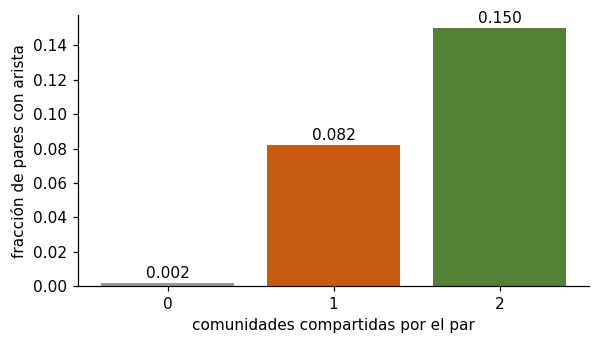

In [4]:
Gg, verdad_g = datos.comunidades_superpuestas(n=600, K=6, solape=0.6, p=0.08, eps=0.002)
Bg = agm.a_matriz(verdad_g, 600)
compartidas = (Bg @ Bg.T)[np.triu_indices(600, 1)]
Ag = nx.to_numpy_array(Gg, nodelist=range(600))[np.triu_indices(600, 1)]

tasas = [Ag[compartidas == k].mean() for k in (0, 1, 2)]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(["0", "1", "2"], tasas, color=["#999999", COLORES[1], COLORES[2]])
for k, t in enumerate(tasas):
    ax.text(k, t + 0.003, f"{t:.3f}", ha="center")
ax.set_xlabel("comunidades compartidas por el par")
ax.set_ylabel("fracción de pares con arista")
plt.show()

## 3. Estimación de máxima verosimilitud (MLE)

La MLE elige los parámetros que hacen más probable lo observado. Con una moneda que dio k caras en n
lanzamientos, la verosimilitud es L(p) = p<sup>k</sup> (1 − p)<sup>n − k</sup>. Conviene maximizar su
logaritmo, que convierte el producto en suma y tiene el mismo máximo:

log L(p) = k log p + (n − k) log(1 − p). Al derivar e igualar a cero se obtiene p̂ = k / n.

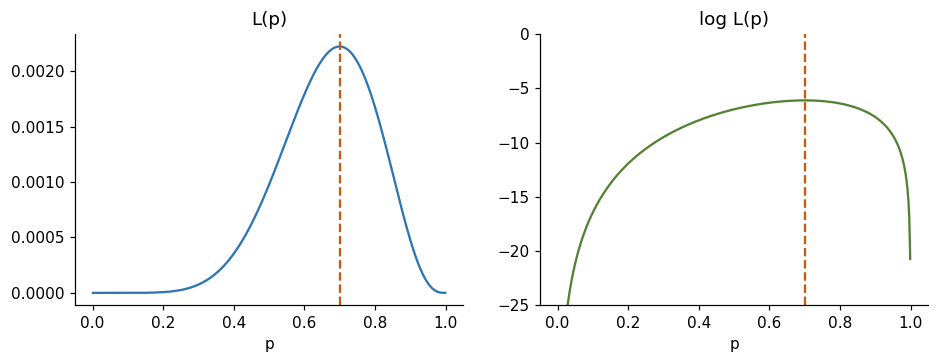

p estimado = 0.699


In [5]:
k, n = 7, 10
ps = np.linspace(0.001, 0.999, 400)
logL = k * np.log(ps) + (n - k) * np.log(1 - ps)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(ps, np.exp(logL), color=COLORES[0]); ax[0].set_title("L(p)")
ax[1].plot(ps, logL, color=COLORES[2]); ax[1].set_ylim(-25, 0); ax[1].set_title("log L(p)")
for a in ax:
    a.axvline(k / n, color=COLORES[1], ls="--"); a.set_xlabel("p")
plt.show()
print("p estimado =", ps[np.argmax(logL)].round(3))

### MLE para el AGM

En el AGM los parámetros son el grafo de afiliación B y las probabilidades p<sub>c</sub>. La verosimilitud
de una red G es el producto de p(u, v) sobre las aristas y de 1 − p(u, v) sobre los pares sin arista.
El paper resuelve el problema por ascenso coordinado en dos bloques:

1. **Actualizar las p con B fijo.** Con el cambio de variable 1 − p<sub>c</sub> = exp(−x<sub>c</sub>) el
logaritmo de la verosimilitud es cóncavo en x, así que hay un óptimo global. Lo resolvemos con L-BFGS-B y su
gradiente analítico en **agm.ajustar_p**.
2. **Actualizar B con las p fijas.** Es una búsqueda combinatoria; se usa Metropolis Hastings con tres
transiciones: LEAVE (u deja una comunidad), JOIN (u se une a otra) y SWITCH (u cambia una por otra).

Primero el paso 1: si conocemos el B verdadero, ¿recuperamos las p?

In [6]:
B_grande = agm.a_matriz(verdad_g, 600)
A_grande = nx.to_numpy_array(Gg, nodelist=range(600))
p_hat = agm.ajustar_p(A_grande, B_grande, eps=0.002)
print("p reales     :", [0.08] * 6)
print("p estimados  :", p_hat.round(3))

p reales     : [0.08, 0.08, 0.08, 0.08, 0.08, 0.08]
p estimados  : [0.082 0.077 0.082 0.077 0.078 0.083]


Ahora el ajuste completo sobre un grafo pequeño de 45 nodos y 3 comunidades. El paper escribe la probabilidad de
aceptación como max(1, L' / L), lo que aceptaría todo; la regla de Metropolis Hastings correcta es
min(1, L' / L), que en logaritmos se implementa como log(r) menor que log L' − log L.

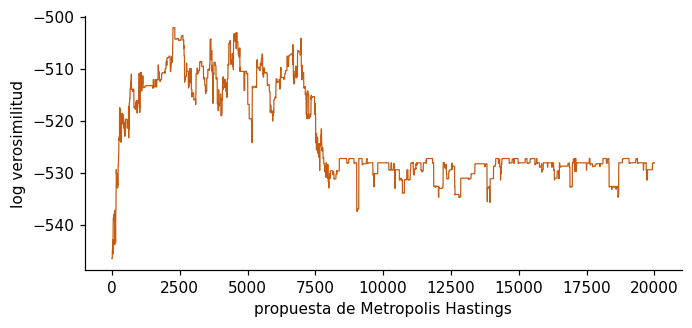

p ajustados: [0.   0.5  0.43]
F1 contra las comunidades reales: 0.8


In [7]:
G45, verdad45 = datos.comunidades_superpuestas(n=45, K=3, solape=0.25, p=0.5, eps=0.01, semilla=1)
A45 = nx.to_numpy_array(G45, nodelist=range(45))
B_fit, p_fit, traza_mh = agm.ajustar(A45, 3, pasos=20000, cada=50, rng=0)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(traza_mh, color=COLORES[1], lw=0.8)
ax.set_xlabel("propuesta de Metropolis Hastings"); ax.set_ylabel("log verosimilitud")
plt.show()
print("p ajustados:", p_fit.round(2))
print("F1 contra las comunidades reales:", round(metricas.f1_promedio(verdad45, agm.a_conjuntos(B_fit)), 3))

El F1 es razonable, pero una de las comunidades terminó con p = 0: el ajuste cayó en un óptimo local, algo que el
paper advierte porque el problema no es convexo en B. Además la cadena mejora poco a poco y cada propuesta cuesta O(N² K), porque hay que reevaluar la verosimilitud de todos
los pares. Con miles de nodos esto se vuelve impracticable: esa es la motivación de BigCLAM.

## 4. BigCLAM

### 4.1 Relajación continua: la matriz F

Con el cambio de variable anterior, p(u, v) = 1 − exp(−Σ<sub>c</sub> x<sub>c</sub> B<sub>uc</sub> B<sub>vc</sub>).
Si definimos F<sub>uc</sub> = √x<sub>c</sub> · B<sub>uc</sub> y dejamos que tome cualquier valor no negativo,
obtenemos el modelo de BigCLAM:

p(u, v) = 1 − exp(−F<sub>u</sub> · F<sub>v</sub>)

F<sub>uc</sub> ya no dice solo si u pertenece a c, sino con qué fuerza. Equivale a suponer que cada comunidad
genera interacciones de Poisson con media F<sub>uc</sub> F<sub>vc</sub> y que vemos una arista si hubo al menos una.

### 4.2 Función objetivo: log verosimilitud

l(F) = Σ<sub>(u,v) ∈ E</sub> log(1 − exp(−F<sub>u</sub> · F<sub>v</sub>)) − Σ<sub>(u,v) ∉ E</sub> F<sub>u</sub> · F<sub>v</sub>

El primer término premia que los vecinos compartan comunidades; el segundo castiga que las compartan pares sin arista.

### 4.3 Gradiente ascendente coordinado

Con todas las filas fijas salvo F<sub>u</sub>, el subproblema es cóncavo y su gradiente es

∇l(F<sub>u</sub>) = Σ<sub>v ∈ N(u)</sub> F<sub>v</sub> exp(−F<sub>u</sub>·F<sub>v</sub>) / (1 − exp(−F<sub>u</sub>·F<sub>v</sub>)) − Σ<sub>v ∉ N(u)</sub> F<sub>v</sub>

El segundo término se obtiene en O(grado de u) guardando S = Σ<sub>v</sub> F<sub>v</sub>, porque
Σ<sub>v ∉ N(u)</sub> F<sub>v</sub> = S − F<sub>u</sub> − Σ<sub>v ∈ N(u)</sub> F<sub>v</sub>. Cada actualización da un paso
de gradiente con búsqueda lineal (Armijo) y proyecta sobre F ≥ 0.

Antes de usar el gradiente lo verificamos contra diferencias finitas:

In [8]:
rng = np.random.default_rng(0)
x = rng.random(3); Y = rng.random((5, 3)); resto = rng.random(3) * 4
analitico = bigclam.gradiente_fila(x, Y, resto)
h = 1e-6
numerico = np.array([(bigclam.objetivo_fila(x + h * e, Y, resto) - bigclam.objetivo_fila(x - h * e, Y, resto)) / (2 * h)
                     for e in np.eye(3)])
print("analítico :", analitico)
print("numérico  :", numerico)

analítico : [1.8   4.476 5.659]
numérico  : [1.8   4.476 5.659]


### 4.4 Ajuste paso a paso

Usamos un grafo de 30 nodos con tres comunidades plantadas. La inicialización toma vecindarios localmente mínimos:
N(u) = {u} ∪ vecinos(u) es semilla si su conductancia es menor que la de todos sus vecinos (Gleich y Seshadhri, 2012).

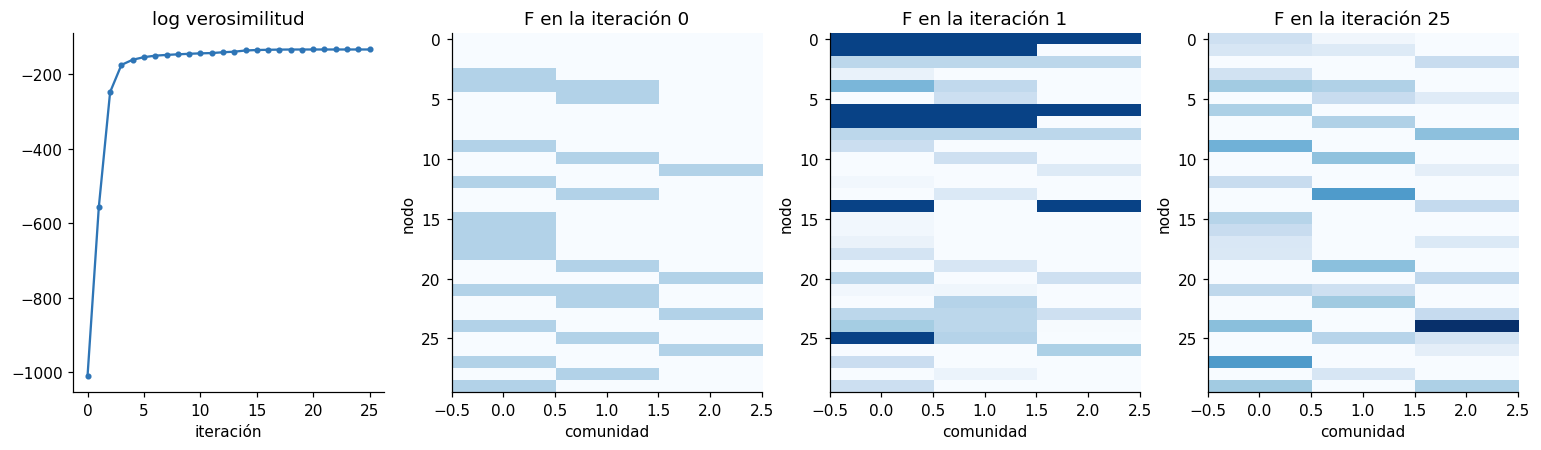

iteraciones: 25, delta = 0.560
comunidad 0: [0, 3, 4, 6, 9, 12, 15, 16, 21, 24, 27, 29]
comunidad 1: [4, 5, 7, 10, 13, 19, 21, 22, 25]
comunidad 2: [2, 8, 14, 20, 23, 24, 25, 29]
F1 promedio: 0.849


In [9]:
G30, verdad30 = datos.comunidades_superpuestas(n=30, K=3, solape=0.3, p=0.5, eps=0.02, semilla=3)
V30 = datos.vecinos(G30)
F, traza, fotos = bigclam.ajustar(V30, 3, rng=0, historial=True)
delta = bigclam.umbral(V30)

fig, ax = plt.subplots(1, 4, figsize=(14, 4.2))
ax[0].plot(traza, "o-", color=COLORES[0], ms=3); ax[0].set_title("log verosimilitud"); ax[0].set_xlabel("iteración")
for a, it in zip(ax[1:], [0, 1, len(fotos) - 1]):
    a.imshow(fotos[it], aspect="auto", cmap="Blues", vmin=0, vmax=fotos[-1].max())
    a.set_title(f"F en la iteración {it}"); a.set_xlabel("comunidad"); a.set_ylabel("nodo")
plt.tight_layout(); plt.show()

detectadas = bigclam.comunidades(F, delta)
print(f"iteraciones: {len(traza) - 1}, delta = {delta:.3f}")
for c, nodos in enumerate(detectadas):
    print(f"comunidad {c}: {sorted(int(u) for u in nodos)}")
print("F1 promedio:", round(metricas.f1_promedio(verdad30, detectadas), 3))

### 4.5 Umbral y número de comunidades

Un nodo pertenece a c si F<sub>uc</sub> ≥ δ, con δ = √(−log(1 − ε)) y ε la densidad de fondo 2|E| / (N(N − 1)).
Así dos miembros de c se conectan con probabilidad mayor que el fondo.

Para elegir K el paper reserva el 20 % de los pares, ajusta con el resto y se queda con el K de mayor
verosimilitud en los pares reservados. El BIC que propone para grafos muy pequeños penaliza N · K · log|E| y en
nuestros grafos elige siempre K = 1, así que usamos la validación.

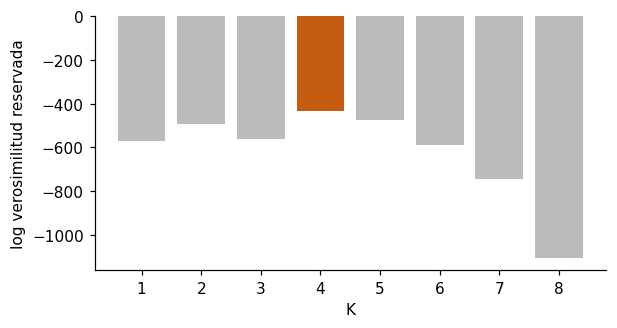

K elegido: 4  K real: 4


In [10]:
G120, verdad120 = datos.comunidades_superpuestas()
K_elegido, puntaje = bigclam.elegir_K(datos.vecinos(G120), range(1, 9))
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(list(puntaje), list(puntaje.values()), color=[COLORES[1] if k == K_elegido else "#BBBBBB" for k in puntaje])
ax.set_xlabel("K"); ax.set_ylabel("log verosimilitud reservada")
plt.show()
print("K elegido:", K_elegido, " K real:", len(verdad120))

### 4.6 Caso real: club de karate

Con K = 2 la comunidad dominante de cada nodo (la columna con mayor F<sub>u</sub>) reproduce la división real del
club casi por completo. La ventaja frente a una partición es que F muestra cuánto pertenece cada nodo a cada lado.

comunidad dominante igual al club real en 33 de 34 nodos
nodos con membresía más mezclada: [ 9  8 19 28 30 27]


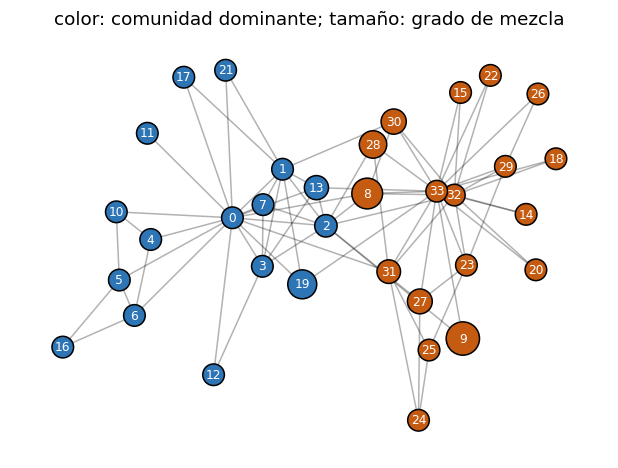

In [11]:
K = nx.karate_club_graph()
Vk = datos.vecinos(K)
Fk, _ = bigclam.ajustar(Vk, 2, rng=0)
club = np.array([K.nodes[u]["club"] == "Officer" for u in K])
dominante = Fk.argmax(1)
aciertos = max((dominante == club).sum(), (dominante != club).sum())
print(f"comunidad dominante igual al club real en {aciertos} de 34 nodos")

mezcla = Fk.min(1) / np.maximum(Fk.max(1), 1e-9)
print("nodos con membresía más mezclada:", np.argsort(-mezcla)[:6])

pos = nx.spring_layout(K, seed=7)
fig, ax = plt.subplots(figsize=(7, 5))
nx.draw_networkx_edges(K, pos, alpha=0.3, ax=ax)
colores = [COLORES[0] if d == 0 else COLORES[1] for d in dominante]
tamanos = 200 + 400 * mezcla
nx.draw_networkx_nodes(K, pos, node_color=colores, node_size=tamanos, edgecolors="k", ax=ax)
nx.draw_networkx_labels(K, pos, font_size=8, font_color="white", ax=ax)
ax.set_title("color: comunidad dominante; tamaño: grado de mezcla"); ax.axis("off")
plt.show()

## 5. AGM dirigido: membresías con dirección

En una red dirigida un nodo puede enviar aristas a una comunidad, recibirlas o ambas cosas. El modelo dirigido
une u con v si hay un camino u → c → v en el grafo de afiliación; al relajarlo como en BigCLAM se obtienen dos
matrices no negativas:

p(u → v) = 1 − exp(−F<sub>u</sub> · H<sub>v</sub>), con F la membresía saliente y H la entrante.

Una comunidad **cohesiva** tiene F y H altos en los mismos nodos. Una comunidad de **dos modos** tiene F alto en
unos nodos (fans) y H alto en otros (famosos). El ajuste alterna actualizar F con H fijo y H con F fijo, y cada
fila es exactamente el subproblema de BigCLAM, por eso **coda.py** reutiliza **bigclam.actualizar_fila**.

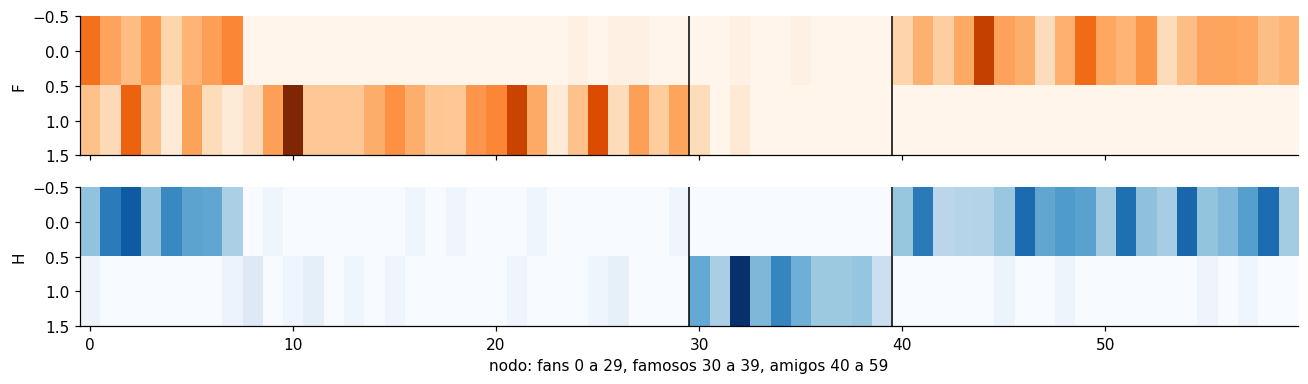

comunidad 0: envían 26 nodos (8 fans), reciben 28 nodos (0 famosos)
comunidad 1: envían 23 nodos (23 fans), reciben 9 nodos (9 famosos)


In [12]:
D, verdad_d = datos.dos_modos()
n = D.number_of_nodes()
salientes = [sorted(D.successors(u)) for u in range(n)]
entrantes = [sorted(D.predecessors(u)) for u in range(n)]
Fd, Hd, traza_d = coda.ajustar(salientes, entrantes, 2, rng=0)

fig, ax = plt.subplots(2, 1, figsize=(12, 3.6), sharex=True)
ax[0].imshow(Fd.T, aspect="auto", cmap="Oranges"); ax[0].set_ylabel("F")
ax[1].imshow(Hd.T, aspect="auto", cmap="Blues"); ax[1].set_ylabel("H")
for a in ax:
    for x in (29.5, 39.5):
        a.axvline(x, color="k", lw=1)
ax[1].set_xlabel("nodo: fans 0 a 29, famosos 30 a 39, amigos 40 a 59")
plt.tight_layout(); plt.show()

delta_d = np.sqrt(-np.log1p(-D.number_of_edges() / (n * (n - 1))))
fans, famosos = verdad_d["dos modos"]
for c, (envian, reciben) in enumerate(coda.comunidades(Fd, Hd, delta_d)):
    print(f"comunidad {c}: envían {len(envian)} nodos ({len(envian & fans)} fans), "
          f"reciben {len(reciben)} nodos ({len(reciben & famosos)} famosos)")

BigCLAM sobre la misma red sin dirección no puede separar los roles: los fans no se conectan entre sí, así que
no forman un grupo denso.

In [13]:
Vd = datos.vecinos(D.to_undirected())
Fb, _ = bigclam.ajustar(Vd, 2, rng=0)
for c, nodos in enumerate(bigclam.comunidades(Fb, bigclam.umbral(Vd))):
    print(f"BigCLAM comunidad {c}: {len(nodos)} nodos, {len(nodos & fans)} fans, {len(nodos & famosos)} famosos")

BigCLAM comunidad 0: 28 nodos, 8 fans, 0 famosos
BigCLAM comunidad 1: 12 nodos, 3 fans, 9 famosos


## 6. Propuestas que atacan las debilidades

AGM y BigCLAM tienen debilidades conocidas: hay que fijar K, el ajuste cae en óptimos locales, ignoran los
atributos de los nodos, no generalizan a nodos nuevos y cada iteración recorre todo el grafo. Implementamos tres
propuestas que atacan una de ellas cada una:

1. **Ego-splitting** (Epasto, Lattanzi y Paes Leme, KDD 2017): obtiene solape a partir de cualquier algoritmo de
partición rápido, sin K ni umbral.
2. **NMF bayesiana con ARD** (Psorakis et al., Phys. Rev. E 2011): la prior apaga las comunidades sobrantes, así
que K se elige solo.
3. **NOCD** (Shchur y Günnemann, 2019): una red neuronal de grafos produce F a partir de la red y de los
atributos, con la misma verosimilitud de BigCLAM.

Dos trabajos de 2025 siguen esta línea: LQ-GCN, que añade la modularidad local al decodificador de Bernoulli Poisson,
y META-CODE, que detecta comunidades cuando la red solo se conoce en parte. Se describen en la presentación, pero
no se reimplementan.

### 6.1 Ego-splitting

1. Paso local: para cada nodo u se particiona su ego-net, que son sus vecinos sin u. Cada parte da una persona de u.
2. Cada arista (u, v) se lleva al grafo de personas: une la persona de u que ve a v con la persona de v que ve a u.
3. Paso global: se particiona el grafo de personas.
4. Cada grupo de personas se traduce a sus nodos originales; un nodo con varias personas queda en varias comunidades.

Reproducimos la figura 1 del paper, con componentes conexas en ambos pasos:

In [14]:
import ego_splitting, bnmf, alternativas

Gt = nx.Graph([("a", "b"), ("a", "c"), ("b", "c"), ("c", "d"), ("c", "e"), ("c", "f"), ("d", "e"),
               ("d", "f"), ("e", "f"), ("f", "g"), ("f", "h"), ("g", "h")])
P, persona = ego_splitting.grafo_de_personas(Gt)
print("personas de c:", persona["c"])
print("personas de f:", persona["f"])
print("aristas del grafo de personas:", sorted(P.edges()))
print("comunidades:", ego_splitting.ego_splitting(Gt, global_=ego_splitting.componentes, minimo=2))

personas de c: {'a': 0, 'b': 0, 'f': 1, 'e': 1, 'd': 1}
personas de f: {'e': 0, 'd': 0, 'c': 0, 'h': 1, 'g': 1}
aristas del grafo de personas: [(('a', 0), ('b', 0)), (('a', 0), ('c', 0)), (('b', 0), ('c', 0)), (('c', 1), ('d', 0)), (('c', 1), ('e', 0)), (('c', 1), ('f', 0)), (('d', 0), ('e', 0)), (('d', 0), ('f', 0)), (('e', 0), ('f', 0)), (('f', 1), ('g', 0)), (('f', 1), ('h', 0)), (('g', 0), ('h', 0))]
comunidades: [{'a', 'c', 'b'}, {'e', 'f', 'c', 'd'}, {'f', 'h', 'g'}]


Al quitar c de su propia ego-net, {a, b} y {d, e, f} quedan desconectados: c se parte en dos personas. Lo mismo
pasa con f. El grafo de personas queda en tres componentes, que son las tres comunidades del paper.

En grafos reales el paso global usa Louvain. Su costo es armar las ego-nets, del orden de Σ grado², más una
partición de un grafo con |E| aristas: por eso escala a miles de millones de aristas.

### 6.2 NMF bayesiana: K automático

Factoriza V = A + diag(grado) como W H con verosimilitud de Poisson. Cada comunidad k tiene una precisión β<sub>k</sub>
en su prior: si la comunidad explica pocos datos, sus pesos bajan, β<sub>k</sub> sube y la prior la empuja a cero.
Las actualizaciones son multiplicativas (ecuaciones 17 a 19 del paper):

1. H ← H / (Wᵀ 1 + B H) · Wᵀ (V / W H)
2. W ← W / (1 Hᵀ + W B) · (V / W H) Hᵀ
3. β<sub>k</sub> ← (N + a − 1) / (½ Σ<sub>i</sub> w<sub>ik</sub>² + ½ Σ<sub>j</sub> h<sub>kj</sub>² + b)

Partimos de 30 comunidades en el grafo sin solape de 4 comunidades:

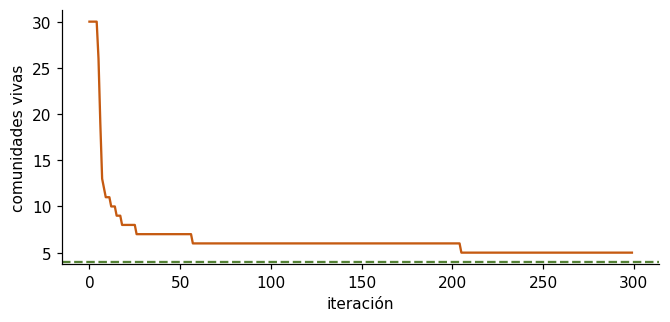

comunidades vivas al final: 5  F1: 0.904


solape 0.2: K = 8, F1 = 0.703


solape 0.4: K = 10, F1 = 0.510


solape 0.6: K = 12, F1 = 0.384


In [15]:
G0, verdad0 = datos.comunidades_superpuestas(solape=0.0)
A0 = nx.to_numpy_array(G0, nodelist=range(120))
W, H, fotos_bn = bnmf.ajustar(A0, K_max=30, iteraciones=300, historial=True)
vivas = [f["activas"] for f in fotos_bn]

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(vivas, color=COLORES[1]); ax.axhline(4, color=COLORES[2], ls="--")
ax.set_xlabel("iteración"); ax.set_ylabel("comunidades vivas")
plt.show()
print("comunidades vivas al final:", vivas[-1], " F1:", round(metricas.f1_promedio(verdad0, bnmf.comunidades(W, H)), 3))

for s in (0.2, 0.4, 0.6):
    Gs, vs = datos.comunidades_superpuestas(solape=s)
    Ws, Hs = bnmf.ajustar(nx.to_numpy_array(Gs, nodelist=range(120)), K_max=30)
    print(f"solape {s}: K = {bnmf.activas(Ws, Hs).sum()}, F1 = {metricas.f1_promedio(vs, bnmf.comunidades(Ws, Hs)):.3f}")

Sin solape, el modelo apaga 25 de las 30 comunidades y queda con 5, cerca de las 4 reales, sin probar varios K. Con solape
crea comunidades extra: una factorización aditiva explica mejor el bloque denso de cada zona solapada con un
componente propio, mientras que el AGM lo explica con la combinación de dos comunidades. Es un buen ejemplo de que
cada modelo trae su propia idea de qué es una comunidad.

### 6.3 NOCD: BigCLAM con una red neuronal de grafos

NOCD conserva el decodificador y la pérdida de BigCLAM, pero F ya no es una tabla de parámetros: es la salida de
una GCN de dos capas, F = ReLU(Â ReLU(Â X W<sub>1</sub>) W<sub>2</sub>), con Â la adyacencia normalizada. Ventajas:
sirve para nodos nuevos, puede usar atributos X y se entrena por lotes. Probamos la red ego 414 con X = A y con los
rasgos anonimizados del perfil:

In [16]:
Gf, circulos, Xf = datos.facebook_ego(414, atributos=True)
print("nodos:", Gf.number_of_nodes(), " rasgos por nodo:", Xf.shape[1], " círculos:", len(circulos))
sin_atributos = alternativas.nocd(Gf, len(circulos))
con_atributos = alternativas.nocd(Gf, len(circulos), X=Xf)
print("NOCD con X = A        :", round(metricas.f1_promedio(circulos, sin_atributos), 3))
print("NOCD con atributos    :", round(metricas.f1_promedio(circulos, con_atributos), 3))
print("Ego-splitting         :", round(metricas.f1_promedio(circulos, ego_splitting.ego_splitting(Gf)), 3))

nodos: 148  rasgos por nodo: 105  círculos: 7


NOCD con X = A        : 0.697
NOCD con atributos    : 0.65
Ego-splitting         : 0.728


En esta red los rasgos del perfil (anonimizados y muy dispersos) no mejoran a NOCD: la estructura ya explica los
círculos mejor que los atributos. Ego-splitting, en cambio, queda a la altura de los mejores con una fracción del
tiempo.

## 7. Comparación

Comparamos BigCLAM con métodos de partición (Louvain, Leiden, propagación de etiquetas), con métodos de solape
clásicos (CPM y SLPA) y con las tres propuestas de la sección anterior.

Los resultados vienen de **experimentos.py**, que promedia tres grafos por nivel de solape (la corrida completa
tarda unos cinco minutos, sobre todo por CPM en Facebook).

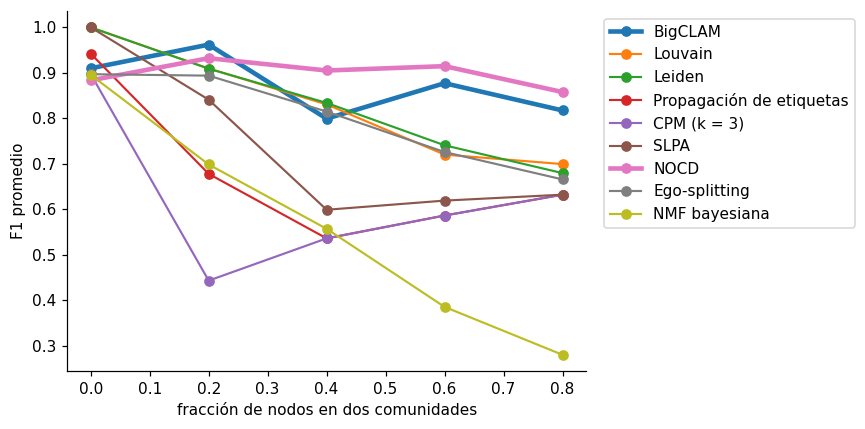

In [17]:
bench = json.loads((RAIZ / "resultados" / "benchmark.json").read_text())
fig, ax = plt.subplots(figsize=(8, 4))
for nombre, f1 in bench["f1"].items():
    grueso = nombre in ("BigCLAM", "NOCD")
    ax.plot(bench["solape"], f1, "o-", lw=3 if grueso else 1.4, label=nombre)
ax.set_xlabel("fracción de nodos en dos comunidades"); ax.set_ylabel("F1 promedio")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

Con solape nulo las particiones son perfectas; a medida que crece el solape caen, mientras BigCLAM y NOCD se
mantienen por encima de 0.8. Ego-splitting sigue a Louvain, que usa en el paso global: hereda su calidad. La NMF
bayesiana cae porque fragmenta las zonas solapadas.

En las redes ego de Facebook (SNAP), con los círculos sociales como referencia, el panorama es más parejo:

In [18]:
fb = json.loads((RAIZ / "resultados" / "facebook.json").read_text())
metodos = ["BigCLAM", "NOCD", "NOCD con atributos", "Ego-splitting", "NMF bayesiana", "SLPA", "CPM (k = 3)",
           "Leiden", "Louvain", "Propagación de etiquetas"]
print(f"{'ego':>5} " + " ".join(f"{m[:10]:>11}" for m in metodos))
for ego, fila in fb.items():
    print(f"{ego:>5} " + " ".join(f"{fila[m]:>11.3f}" for m in metodos))
print()
print("segundos por método")
for ego, fila in fb.items():
    print(f"{ego:>5} " + " ".join(f"{fila['t ' + m]:>11.2f}" if 't ' + m in fila else f"{'':>11}" for m in metodos))

  ego     BigCLAM        NOCD  NOCD con a  Ego-splitt  NMF bayesi        SLPA  CPM (k = 3      Leiden     Louvain  Propagació
  414       0.602       0.669       0.596       0.728       0.511       0.725       0.597       0.647       0.574       0.725
  686       0.366       0.584       0.525       0.553       0.415       0.544       0.553       0.495       0.566       0.554
  348       0.505       0.642       0.566       0.506       0.401       0.580       0.474       0.550       0.518       0.462
    0       0.275       0.339       0.324       0.310       0.300       0.326       0.290       0.285       0.286       0.267

segundos por método
  414        3.23        1.47                    0.02        0.18        0.98        4.31        0.01        0.01        0.00
  686        3.69        2.72                    0.03        0.28        0.91        0.71        0.01        0.01        0.00
  348        3.47        3.52                    0.06        0.31        1.78      129.74        

Ningún método domina. NOCD queda primero en tres de las cuatro redes y Ego-splitting en la 414, donde además
tarda unas centésimas de segundo; BigCLAM puro, con K igual al número de círculos, queda por debajo. Los círculos son etiquetas declaradas por cada usuario, muchas veces
incompletas, y K fijo a su número no es necesariamente el mejor para la estructura de la red.

## 8. Conclusiones

1. El AGM explica por qué el solape es más denso: cada comunidad compartida es otra oportunidad de conexión.
2. Su MLE es cóncava en las probabilidades pero combinatoria en B, y Metropolis Hastings escala mal.
3. BigCLAM relaja B a una matriz F no negativa y la ajusta fila por fila en O(grado), con gradiente proyectado.
4. El AGM dirigido (CoDA) separa quién envía y quién recibe, y detecta comunidades de dos modos.
5. Con solape alto, BigCLAM y NOCD superan a las particiones; en datos reales conviene comparar varios métodos.
6. Ego-splitting obtiene solape con el costo de dos particiones; la NMF bayesiana elige K sola pero se fragmenta
con mucho solape; NOCD lleva la verosimilitud de BigCLAM a una red neuronal que generaliza a nodos nuevos.